In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from decision_calibration import tasks

label_fontsize = 11

os.makedirs("figures/cost_fn_overview", exist_ok=True)

# Cost functions

Cost per action over the outcome, for the example parameters shown in the paper.

In [2]:
y_range_frost = np.linspace(-2,5, 1000)
y_range_heat = np.linspace(28,37, 300)
#y_range = np.linspace(20,40, 100)
y_range_wind = np.linspace(0,27,1000)
y_range_power = np.linspace(0,1,100)

### Frost

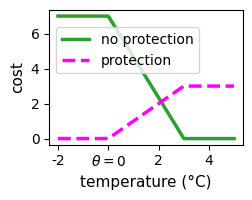

In [3]:
action_map = {0: 'no protection', 1: 'protection'}
task = tasks.FrostTask(threshold=0, cost_ratio=0.7, transition_width=3)

colors = {0: 'C2', 1: 'magenta'}
linestyles = {0: '-', 1: '--'}

fig, ax = plt.subplots(figsize=(2.5,1.75), dpi=100)
for i, action in enumerate(range(task.n_actions)):
    ax.plot(y_range_frost, task.cost(action, y_range_frost), linestyle=linestyles[action], label=action_map[action], c=colors[action], linewidth=2.5)

ax.legend(loc='center left', bbox_to_anchor=(0., 0.7))
ax.set_xticks([-2,0,2,4])
ax.set_xticklabels([-2,r'$\theta=0$',2,4])
ax.set_xlabel('temperature (°C)', fontsize=label_fontsize)
ax.set_ylabel('cost', fontsize=label_fontsize)

plt.show()
fig.savefig('figures/cost_fn_overview/frost_cost_fn.pdf', bbox_inches='tight', transparent=True)

### Heat

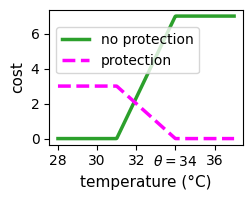

In [4]:
action_map = {0: 'no protection', 1: 'protection'}
task = tasks.HeatTask(threshold=34, cost_ratio=0.7, transition_width=3)

colors = {0: 'C2', 1: 'magenta'}
linestyles = {0: '-', 1: '--'}

fig, ax = plt.subplots(figsize=(2.5,1.75), dpi=100)
for i, action in enumerate(range(task.n_actions)):
    plt.plot(y_range_heat, task.cost(action, y_range_heat), linestyle=linestyles[action], label=action_map[action], c=colors[action], linewidth=2.5)

plt.legend(loc='center left', bbox_to_anchor=(0, 0.7))
plt.xticks([28,30,32,34,36],[28,30,32,r'$\theta=34$',36])
ax.set_xlabel('temperature (°C)', fontsize=label_fontsize)
plt.ylabel('cost', fontsize=11)
plt.show()

fig.savefig('figures/cost_fn_overview/heat_cost_fn.pdf', bbox_inches='tight', transparent=True)

### Windpower

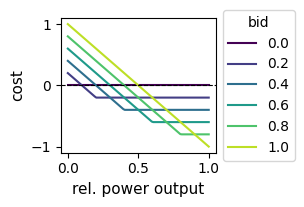

In [5]:
#action_map = {0: 'no action', 1: 'heat protection'}
action_map = {0: 0.0, 1: 0.1, 2: 0.2, 3: 0.3, 4: 0.4, 5: 0.5, 6: 0.6, 7: 0.7, 8: 0.8, 9: 0.9, 10: 1.0}
u_pen = 2.0
task = tasks.WindPowerTask(shortfall_penalty=u_pen, surplus_penalty=0.0, bids=tuple(action_map.values()))
skip_action = 2

#colors = {0: 'C2', 1: 'C3'}
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 0.9, len(range(task.n_actions)[::skip_action])))

fig, ax = plt.subplots(figsize=(2,1.75), dpi=100)
for i, action in enumerate(range(task.n_actions)[::skip_action]):
    #plt.plot(y_range_heat, task.cost(action, y_range_heat), label=action_map[action], c=colors[action])
    plt.plot(y_range_power, task.cost(action, y_range_power), label=action_map[action], color=colors[i], linewidth=1.5)
plt.axhline(0, c='k', ls='--', lw=0.8)
plt.legend(title='bid', loc='center left', bbox_to_anchor=(1, 0.5))
#plt.xticks([28,30,32,34,36],['28','30','32',r'$\theta=34$','36'])
plt.xlabel('rel. power output', fontsize=11)
plt.ylabel('cost', fontsize=11)
plt.show()
fig.savefig('figures/cost_fn_overview/windpower_cost_fn.pdf', bbox_inches='tight')